# Lab B - YOLO i podejście hybrydowe (BDD100K)

Notebook uruchamia cały pipeline Lab B (bez fine-tuningu) i wizualizuje wyniki. Każdy krok wywołuje skrypt
z `labB/code/` (jak w `labB/PLAN.md`) i jest **pomijany, jeśli jego wynik już istnieje i jest nowszy od wejść**,
więc po przerwaniu wystarczy uruchomić notebook ponownie - przerwane predykcje są wznawiane.

**Uruchomienie** (z katalogu głównego repo):
```powershell
uv run jupyter nbconvert --to notebook --execute --inplace labB/run_all.ipynb --ExecutePreprocessor.timeout=-1
```
albo w VS Code: kernel `.venv` -> *Run All*.

**Wyniki do prezentacji:**
* `labB/assets/` - wszystkie wykresy (`B01_...png`, `B02_...png`, ...),
* `labB/assets/tables/` - tabele jako CSV i PNG,
* `labB/assets/examples/` - pojedyncze obrazy przykładowe w pełnej rozdzielczości,
* `labB/results/` - podsumowania JSON/CSV, `summary.md`; logi kroków: `labB/runs/logs/`.

| Sekcja | Zawartość |
|---|---|
| 0 | środowisko, kontrola ewaluacji na predykcjach Lab A |
| 1 | YOLO-COCO: siatka model x imgsz na val1000, wybór, test GPU + CPU, STOP |
| 2 | hybryda YOLO + HSV (H0, H1, oracle) |
| 3 | porównanie z Lab A (P/R/F1, kolor, FPS, te same sygnalizatory, rozbicia) |
| 4 | przykłady błędów, podsumowanie |

Fine-tuning (Zad. 3, wariant rozszerzony) został pominięty, dlatego - zgodnie z treścią zadania dla wariantu
bez fine-tuningu - porównujemy tylko sygnalizatory; dla znaków pokazujemy jedynie, co wykrywa klasa COCO `stop sign`.

In [1]:
import collections, json, os, random, subprocess, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "labB").exists())
LAB_B, CODE = REPO / "labB", REPO / "labB" / "code"
sys.path.insert(0, str(CODE))
from paths import ASSETS, CONFIGS, IMAGES, LAB_A, RESULTS, RUNS   # noqa: E402
from bdd import COLORS, load_annotation, read_jsonl               # noqa: E402
from common import match_predictions                              # noqa: E402  (Lab A)

PRED, LOGS = RUNS / "predictions", RUNS / "logs"
TABLES, EXAMPLES = ASSETS / "tables", ASSETS / "examples"
for d in (RESULTS, PRED, LOGS, ASSETS, TABLES, EXAMPLES):
    d.mkdir(parents=True, exist_ok=True)

# ---------------- ustawienia ----------------
GRID_MODELS = ["yolo11n", "yolo11s"]
GRID_IMGSZ = [640, 960, 1280]
CPU_LIMIT = 500                      # pomiar FPS na CPU: pierwsze N obrazów testu
COCO_CFG = CONFIGS / "yolo_coco.json"
SAVE_DPI = 150                       # rozdzielczość zapisywanych wykresów (do slajdów)

plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": SAVE_DPI, "axes.grid": True, "grid.alpha": 0.3})
pd.options.display.float_format = "{:.2f}".format
print("repo:", REPO)

repo: c:\Users\tomas\OneDrive\Desktop\lab04


In [2]:
# ---------------- uruchamianie kroków (pomijanie gotowych, logi, wznawianie) ----------------
def fresh(outputs, inputs=()):
    outputs = [Path(o) for o in outputs]
    if not outputs or not all(o.exists() for o in outputs):
        return False
    newest_input = max((Path(i).stat().st_mtime for i in inputs if Path(i).exists()), default=0)
    return min(o.stat().st_mtime for o in outputs) >= newest_input


def _echo(line):
    line = line.rstrip().split("\r")[-1]
    return line if line and "it/s]" not in line and "s/it]" not in line else None


def run(step, args, outputs=(), inputs=(), force=False):
    if not force and fresh(outputs, inputs):
        print(f"[pomijam] {step}")
        return
    cmd = [sys.executable, *map(str, args)]
    log = LOGS / f"{step}.log"
    print(f"[start {time.strftime('%H:%M:%S')}] {step}  (log: {log.relative_to(REPO)})", flush=True)
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
    tail = collections.deque(maxlen=40)
    start = time.time()
    with open(log, "w", encoding="utf-8") as target:
        process = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=env)
        try:
            for raw in process.stdout:
                line = raw.decode("utf-8", "replace")
                target.write(line)
                tail.append(line.rstrip())
                if (shown := _echo(line)):
                    print("   ", shown, flush=True)
            process.wait()
        except KeyboardInterrupt:
            process.kill()
            raise
    if process.returncode:
        raise RuntimeError(f"{step}: kod {process.returncode}, log {log}\n" + "\n".join(tail))
    print(f"[koniec] {step} ({(time.time() - start) / 60:.1f} min)", flush=True)


def predict(name, config, split, subset=None, weights=None, imgsz=None, device="0", limit=None):
    out = PRED / f"{name}.jsonl"
    args = [CODE / "predict.py", "--config", config, "--split", split, "--name", name, "--device", device]
    for flag, value in (("--subset", subset), ("--weights", weights), ("--imgsz", imgsz), ("--limit", limit)):
        if value is not None:
            args += [flag, value]
    run(f"predict_{name}", args, [out, out.with_suffix(".meta.json")], [config])
    return out


def evaluate(name, predictions, split, target, sweep=False, threshold=None, threshold_from=None):
    args = [CODE / "evaluate.py", "--predictions", predictions, "--split", split, "--target", target, "--name", name]
    if sweep:
        args.append("--sweep")
    elif threshold_from is not None:
        args += ["--threshold-from", threshold_from]
    else:
        args += ["--threshold", threshold]
    run(f"eval_{name}", args, [RESULTS / f"{name}.json"], [predictions] + ([threshold_from] if threshold_from else []))
    return RESULTS / f"{name}.json"


def hybrid(name, split, predictions=None, color_config=None, min_score=None, inputs=()):
    out = PRED / f"{name}.jsonl"
    args = [CODE / "hybrid_color.py", "--split", split, "--name", name]
    args += ["--predictions", predictions] if predictions else ["--gt-boxes"]
    if color_config:
        args += ["--color-config", color_config]
    if min_score is not None:
        args += ["--min-score", min_score]
    run(f"hybrid_{name}", args, [out, out.with_suffix(".meta.json")],
        [p for p in (predictions, color_config, *inputs) if p])
    return out


def R(name):
    path = RESULTS / f"{name}.json"
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None


def mean_seconds(path, key="seconds"):
    values = [row.get(key, 0.0) for row in read_jsonl(path)]
    return float(np.mean(values)) if values else None


# ---------------- zapis wykresów, tabel i obrazów (do prezentacji) ----------------
def save(fig, name):
    path = ASSETS / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print("zapisano", path.relative_to(REPO))
    plt.show()


def save_table(df, name, title=None, index=False):
    # tabela -> CSV (do edycji) + PNG (do wklejenia na slajd)
    df.to_csv(TABLES / f"{name}.csv", index=index, encoding="utf-8")
    shown = df.reset_index() if index else df
    text = [[("-" if pd.isna(v) else f"{v:.2f}") if isinstance(v, (float, np.floating)) or v is None
             else str(v) for v in row] for row in shown.itertuples(index=False)]
    width = max(6, 1.25 * len(shown.columns) + 0.06 * max(len(str(c)) for c in shown.columns) * len(shown.columns))
    fig, ax = plt.subplots(figsize=(min(width, 22), 0.45 * (len(shown) + 1) + (0.5 if title else 0.1)))
    ax.axis("off")
    table = ax.table(cellText=text, colLabels=[str(c) for c in shown.columns], loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.auto_set_column_width(range(len(shown.columns)))
    table.scale(1, 1.4)
    for (r, _), cell in table.get_celld().items():
        if r == 0:
            cell.set_facecolor("#dfe6ee")
            cell.set_text_props(weight="bold")
    if title:
        ax.set_title(title, fontsize=11, pad=4)
    fig.savefig(TABLES / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print("zapisano", (TABLES / f"{name}.png").relative_to(REPO), "+ .csv")
    display(df)

## 0. Środowisko i kontrola ewaluacji

In [3]:
import torch, ultralytics
CUDA = torch.cuda.is_available()
print(f"torch {torch.__version__}, ultralytics {ultralytics.__version__}, CUDA: {CUDA}",
      f"({torch.cuda.get_device_name(0)})" if CUDA else "")
if not CUDA:
    print("UWAGA: brak CUDA - predykcje pójdą na CPU (wolno).")

torch 2.11.0+cu128, ultralytics 8.4.216, CUDA: True (NVIDIA GeForce RTX 3060 Laptop GPU)


**Kontrola:** `evaluate.py` (dopasowanie z `labA/code/common.py`) na zapisanych predykcjach testowych Lab A
musi odtworzyć TP/FP/FN i trafność koloru z `labA/assets/test_results.json`.

In [4]:
evaluate("labA_light_test", LAB_A / "predictions/traffic_light_colors.jsonl", "test", "traffic_light", threshold=0)
evaluate("labA_sign_test", LAB_A / "predictions/traffic_sign.jsonl", "test", "traffic_sign", threshold=0)

LAB_A_RESULTS = json.loads((LAB_A / "assets/test_results.json").read_text(encoding="utf-8"))
check = []
for entry in LAB_A_RESULTS["detection"]:
    ours = R("labA_light_test" if entry["class"] == "traffic_light" else "labA_sign_test")
    check.append({"klasa": entry["class"], **{f"{k} (A / B-eval)": f"{entry[k]} / {ours[k]}"
                  for k in ("true_positive", "false_positive", "false_negative")},
                  "zgodne": all(entry[k] == ours[k] for k in ("true_positive", "false_positive", "false_negative"))})
check = pd.DataFrame(check)
save_table(check, "T00_kontrola_labA", "Kontrola: ewaluacja Lab B na predykcjach Lab A")
color_ok = abs(R("labA_light_test")["color"]["color_accuracy_percent"] - LAB_A_RESULTS["color"]["color_accuracy_percent"]) < 1e-6
print("kolor zgodny:", color_ok, f"({LAB_A_RESULTS['color']['color_accuracy_percent']:.2f} %)")
assert check["zgodne"].all() and color_ok, "Ewaluacja Lab B nie odtwarza wyników Lab A!"

[pomijam] eval_labA_light_test
[pomijam] eval_labA_sign_test
zapisano labB\assets\tables\T00_kontrola_labA.png + .csv


,klasa,true_positive (A / B-eval),false_positive (A / B-eval),false_negative (A / B-eval),zgodne
0,traffic_sign,12014 / 12014,50964 / 50964,56978 / 56978,True
1,traffic_light,11773 / 11773,45443 / 45443,41044 / 41044,True


kolor zgodny: True (83.98 %)


## 1. Zadanie 1 - YOLO wytrenowany na COCO

Klasy COCO użyte do oceny: `traffic light` (9) i `stop sign` (11). Detekcje zapisywane od `conf = 0.01`,
próg wybierany na **val1000** (1000 obrazów val, losowanie jak w Lab A) jako best-F1.

### 1.1. Strojenie na val1000: model x imgsz

In [5]:
grid = []
for m in GRID_MODELS:
    for s in GRID_IMGSZ:
        name = f"coco_{m}_{s}"
        preds = predict(f"{name}_val1000", COCO_CFG, "val", subset="val1000", weights=f"{m}.pt", imgsz=s)
        evaluate(f"{name}_val_light", preds, "val", "traffic_light", sweep=True)
        r = R(f"{name}_val_light")
        grid.append({"name": name, "model": m, "imgsz": s, "próg": r["score_threshold"],
                     "P [%]": r["precision_percent"], "R [%]": r["recall_percent"], "F1 [%]": r["f1_percent"],
                     "ms/obraz": 1000 * r["mean_detection_seconds"], "FPS": r["fps"]})
grid = pd.DataFrame(grid)
# wybór: best F1 (zaokrąglone do 0.1 pp), przy remisie szybszy wariant
grid["_key"] = grid["F1 [%]"].round(1)
BEST = grid.sort_values(["_key", "FPS"], ascending=False).iloc[0]["name"]
grid = grid.drop(columns="_key").sort_values("F1 [%]", ascending=False)
BEST_ROW = grid.set_index("name").loc[BEST]
T_LIGHT = R(f"{BEST}_val_light")["score_threshold"]
save_table(grid.drop(columns="name"), "T01_coco_siatka_val1000", "YOLO-COCO: światła na val1000 (próg best-F1)")
print(f"Wybrany wariant: {BEST} (model {BEST_ROW['model']}, imgsz {BEST_ROW['imgsz']}), próg świateł {T_LIGHT:.3f}")

[pomijam] predict_coco_yolo11n_640_val1000
[pomijam] eval_coco_yolo11n_640_val_light
[pomijam] predict_coco_yolo11n_960_val1000
[pomijam] eval_coco_yolo11n_960_val_light
[pomijam] predict_coco_yolo11n_1280_val1000
[pomijam] eval_coco_yolo11n_1280_val_light
[pomijam] predict_coco_yolo11s_640_val1000
[pomijam] eval_coco_yolo11s_640_val_light
[pomijam] predict_coco_yolo11s_960_val1000
[pomijam] eval_coco_yolo11s_960_val_light
[pomijam] predict_coco_yolo11s_1280_val1000
[pomijam] eval_coco_yolo11s_1280_val_light
zapisano labB\assets\tables\T01_coco_siatka_val1000.png + .csv


,model,imgsz,próg,P [%],R [%],F1 [%],ms/obraz,FPS
5,yolo11s,1280,0.15,43.44,41.92,42.67,18.05,55.40
4,yolo11s,960,0.15,44.83,33.14,38.11,18.69,53.51
2,yolo11n,1280,0.15,37.42,30.90,33.85,19.38,51.60
1,yolo11n,960,0.12,33.26,25.10,28.61,18.18,55.02
3,yolo11s,640,0.10,30.88,25.02,27.64,18.69,53.51
0,yolo11n,640,0.08,22.08,17.25,19.37,22.98,43.52


Wybrany wariant: coco_yolo11s_1280 (model yolo11s, imgsz 1280), próg świateł 0.147


zapisano labB\assets\B01_coco_siatka.png


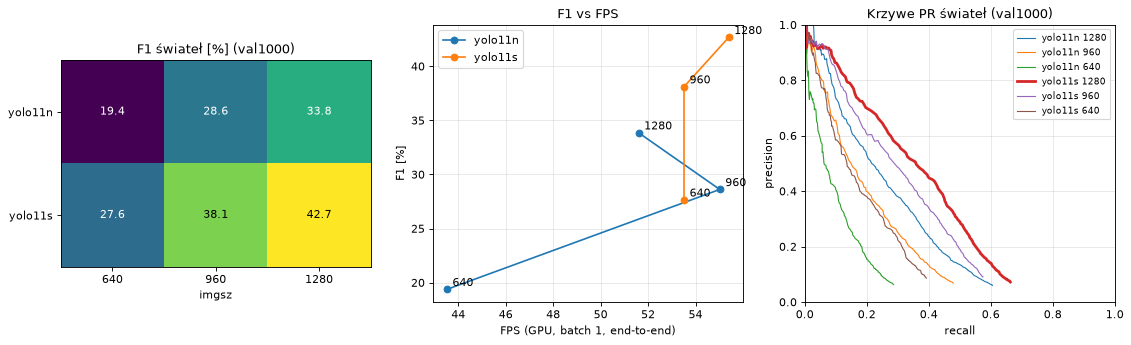

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
pivot = grid.pivot(index="model", columns="imgsz", values="F1 [%]")
axes[0].imshow(pivot.values, cmap="viridis")
axes[0].set(xticks=range(len(pivot.columns)), xticklabels=pivot.columns, yticks=range(len(pivot.index)),
            yticklabels=pivot.index, xlabel="imgsz", title="F1 świateł [%] (val1000)")
axes[0].grid(False)
for (i, j), v in np.ndenumerate(pivot.values):
    axes[0].text(j, i, f"{v:.1f}", ha="center", va="center", color="w" if v < pivot.values.max() - 5 else "k")
for m, sub in grid.groupby("model"):
    sub = sub.sort_values("imgsz")
    axes[1].plot(sub["FPS"], sub["F1 [%]"], "o-", label=m)
    for _, row in sub.iterrows():
        axes[1].annotate(str(row["imgsz"]), (row["FPS"], row["F1 [%]"]), textcoords="offset points", xytext=(5, 3))
axes[1].set(xlabel="FPS (GPU, batch 1, end-to-end)", ylabel="F1 [%]", title="F1 vs FPS")
axes[1].legend()
for m, sub in grid.groupby("model"):
    for _, row in sub.iterrows():
        curve = R(f"{row['name']}_val_light")["pr_curve"]
        axes[2].plot([c["recall"] for c in curve], [c["precision"] for c in curve],
                     lw=2.5 if row["name"] == BEST else 1, label=f"{m} {row['imgsz']}")
axes[2].set(xlabel="recall", ylabel="precision", title="Krzywe PR świateł (val1000)", xlim=(0, 1), ylim=(0, 1))
axes[2].legend(fontsize=8)
save(fig, "B01_coco_siatka")

zapisano labB\assets\B02_coco_recall_wg_rozmiaru.png


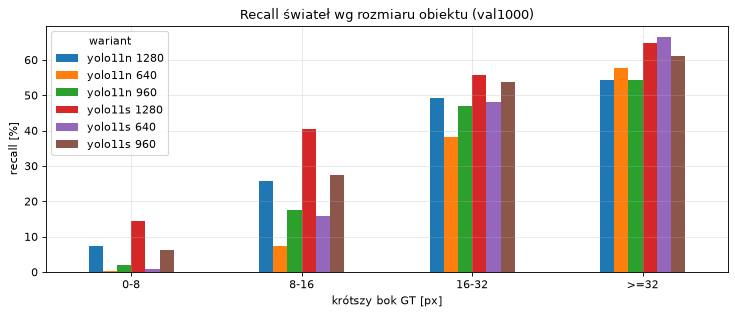

In [7]:
# rozbicie wg rozmiaru (krótszy bok boksu GT w px) - dlaczego imgsz ma znaczenie
rows = []
for _, row in grid.iterrows():
    for size, v in R(f"{row['name']}_val_light")["by_size"].items():
        rows.append({"wariant": f"{row['model']} {row['imgsz']}", "rozmiar": size, "recall": v["recall_percent"]})
by_size = pd.DataFrame(rows).pivot(index="rozmiar", columns="wariant", values="recall")
by_size = by_size.loc[[s for s in ("0-8", "8-16", "16-32", ">=32") if s in by_size.index]]
ax = by_size.plot.bar(figsize=(11, 4), rot=0, title="Recall świateł wg rozmiaru obiektu (val1000)")
ax.set(ylabel="recall [%]", xlabel="krótszy bok GT [px]")
save(ax.figure, "B02_coco_recall_wg_rozmiaru")

### 1.2. Test (20 000 obrazów) - GPU oraz pomiar FPS na CPU

In [8]:
best_model, best_imgsz = f"{BEST_ROW['model']}.pt", int(BEST_ROW["imgsz"])

# wcześniejsze ręczne przebiegi z PLAN.md (--name coco_test / coco_test_cpu500, config yolo_coco.json)
# przejmujemy, jeśli to ten sam wariant (niedokończone są wznawiane przez predict.py)
cfg = json.loads(COCO_CFG.read_text(encoding="utf-8"))
if (cfg["weights"], cfg["imgsz"]) == (best_model, best_imgsz):
    for old, new in (("coco_test", f"{BEST}_test"), (f"coco_test_cpu{CPU_LIMIT}", f"{BEST}_test_cpu{CPU_LIMIT}")):
        if (PRED / f"{old}.jsonl").exists() and not (PRED / f"{new}.jsonl").exists():
            for suffix in (".jsonl", ".meta.json"):
                if (PRED / f"{old}{suffix}").exists():
                    (PRED / f"{old}{suffix}").rename(PRED / f"{new}{suffix}")
            print(f"przejęto {old}.jsonl -> {new}.jsonl")

COCO_TEST = predict(f"{BEST}_test", COCO_CFG, "test", weights=best_model, imgsz=best_imgsz)
evaluate(f"{BEST}_light_test", COCO_TEST, "test", "traffic_light", threshold_from=RESULTS / f"{BEST}_val_light.json")
COCO_CPU = predict(f"{BEST}_test_cpu{CPU_LIMIT}", COCO_CFG, "test", weights=best_model, imgsz=best_imgsz,
                   device="cpu", limit=CPU_LIMIT)
r = R(f"{BEST}_light_test")
print(f"TEST światła: P {r['precision_percent']:.2f}  R {r['recall_percent']:.2f}  F1 {r['f1_percent']:.2f}  "
      f"| GPU {r['fps']:.1f} FPS | CPU {1 / mean_seconds(COCO_CPU):.2f} FPS (pierwsze {CPU_LIMIT} obrazów)")

[pomijam] predict_coco_yolo11s_1280_test
[pomijam] eval_coco_yolo11s_1280_light_test
[pomijam] predict_coco_yolo11s_1280_test_cpu500
TEST światła: P 40.34  R 38.44  F1 39.37  | GPU 39.5 FPS | CPU 6.42 FPS (pierwsze 500 obrazów)


### 1.3. Znak STOP

BDD100K ma jedną, ogólną klasę `traffic sign`, więc detekcje COCO `stop sign` porównujemy ze **wszystkimi** znakami GT:
precyzja = "czy wykryty STOP jest w ogóle znakiem", recall jest tylko informacyjny (STOP to ułamek znaków).

[pomijam] eval_coco_yolo11s_1280_val_stop
[pomijam] eval_coco_yolo11s_1280_stop_test
STOP (test, próg 0.010): detekcje 3464, TP 2046, FP 1418, P 59.1 %, R 2.97 % z 68992 znaków
zapisano labB\assets\B03_stop_precyzja.png


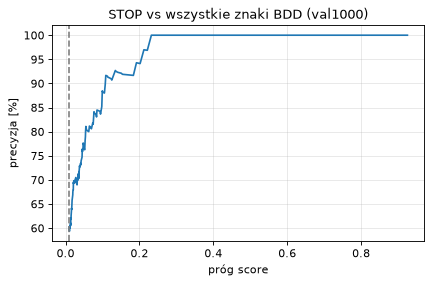

In [9]:
COCO_VAL = PRED / f"{BEST}_val1000.jsonl"
evaluate(f"{BEST}_val_stop", COCO_VAL, "val", "stop_sign", sweep=True)
evaluate(f"{BEST}_stop_test", COCO_TEST, "test", "stop_sign", threshold_from=RESULTS / f"{BEST}_val_stop.json")
T_STOP = R(f"{BEST}_val_stop")["score_threshold"]
s = R(f"{BEST}_stop_test")
print(f"STOP (test, próg {T_STOP:.3f}): detekcje {s['true_positive'] + s['false_positive']}, "
      f"TP {s['true_positive']}, FP {s['false_positive']}, P {s['precision_percent']:.1f} %, "
      f"R {s['recall_percent']:.2f} % z {s['ground_truth_objects']} znaków")
curve = R(f"{BEST}_val_stop")["pr_curve"]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot([c["score_threshold"] for c in curve], [100 * c["precision"] for c in curve])
ax.axvline(T_STOP, ls="--", c="gray")
ax.set(xlabel="próg score", ylabel="precyzja [%]", title="STOP vs wszystkie znaki BDD (val1000)")
save(fig, "B03_stop_precyzja")

### 1.4. Podgląd jakościowy (val): dzień / noc / deszcz

zapisano labB\assets\B04_coco_podglad_val.png


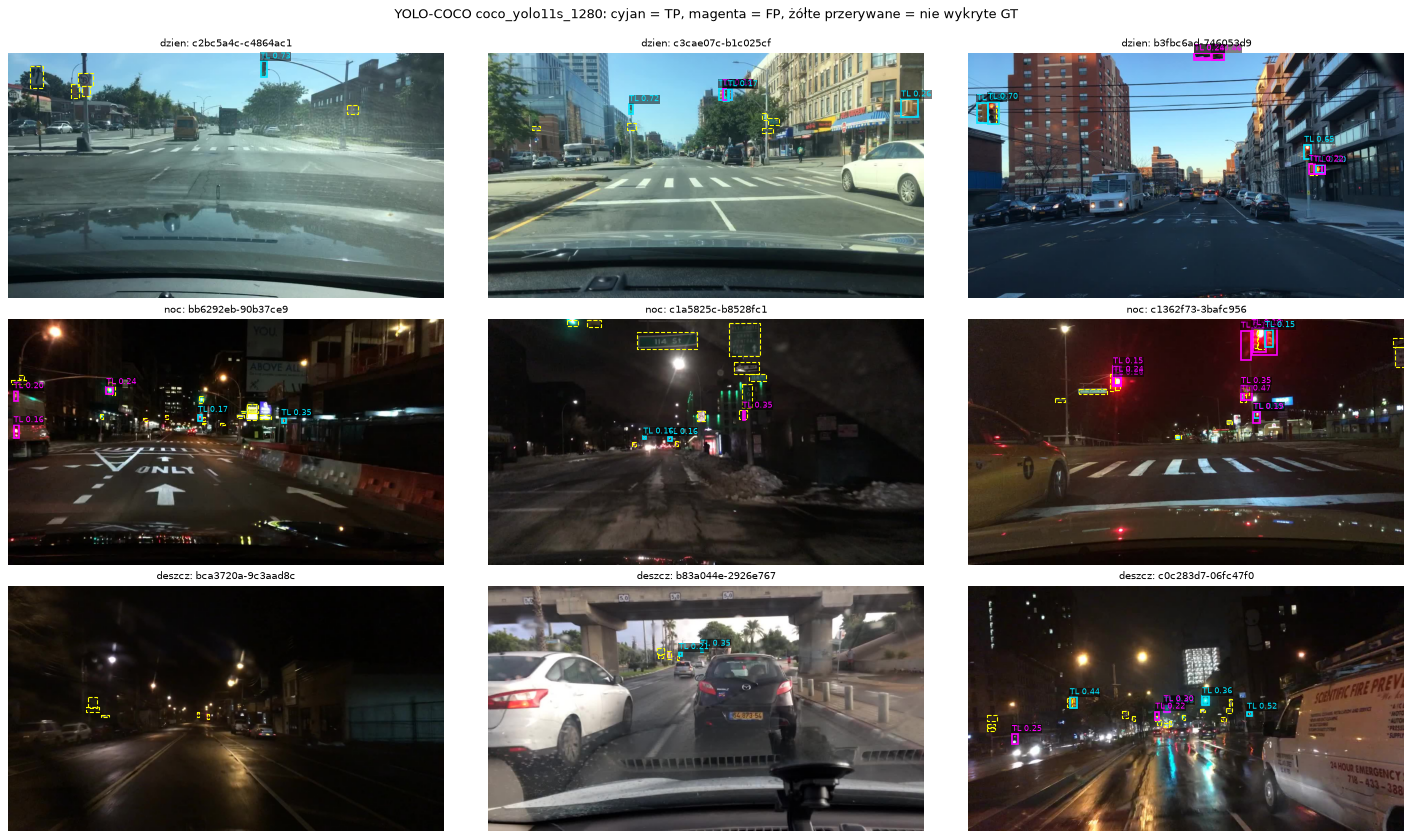

pojedyncze obrazy: labB\assets\examples/podglad_*.png


In [10]:
def is_light(c): return c.startswith("traffic_light")


def draw_box(ax, box, color, ls="-", lw=1.5, text=None, fontsize=7):
    ax.add_patch(patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], fill=False,
                                   edgecolor=color, ls=ls, lw=lw))
    if text:
        ax.text(box[0], box[1] - 3, text, color=color, fontsize=fontsize, va="bottom",
                bbox=dict(facecolor="black", alpha=0.5, pad=0.5, lw=0))


def show_image(ax, split, row, layers, title="", fontsize=7):
    # layers: lista (gt_key, accept(class), próg). TP = cyjan, FP = magenta, FN (GT bez trafienia) = żółte przerywane
    ann = load_annotation(split, row["image_id"])
    with Image.open(IMAGES / split / row["image_filename"]) as img:
        ax.imshow(img.convert("RGB"))
    for gt_key, accept, thr in layers:
        preds = [p for p in row["predictions"] if accept(p["class"]) and p["score"] >= thr]
        res = match_predictions(preds, ann[gt_key], 0.5)
        for miss in res["unmatched_targets"]:
            draw_box(ax, miss["box"], "yellow", ls="--", lw=1)
        for m in res["matched_predictions"]:
            label = m.get("color") or m["class"].replace("traffic_light", "TL").replace("stop_sign", "STOP")
            draw_box(ax, m["box"], "#00e5ff" if m["result"] == "true_positive" else "magenta",
                     text=f"{label} {m['score']:.2f}", fontsize=fontsize)
    ax.set_title(title or f"{row['image_id']}  ({ann['timeofday']}, {ann['weather']})", fontsize=9)
    ax.axis("off")


def save_example(split, row, layers, title, file):
    # pojedynczy obraz w pełnej rozdzielczości (1280x720) -> labB/assets/examples/
    fig = plt.figure(figsize=(12.8, 7.2), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1])
    show_image(ax, split, row, layers, title="", fontsize=10)
    ax.text(10, 25, title, color="white", fontsize=12, bbox=dict(facecolor="black", alpha=0.6, lw=0))
    fig.savefig(EXAMPLES / f"{file}.png", dpi=100, facecolor="black")
    plt.close(fig)


val_rows = {r["image_id"]: r for r in read_jsonl(COCO_VAL)}
groups = {"dzien": lambda a: a["timeofday"] == "daytime" and a["weather"] == "clear",
          "noc": lambda a: a["timeofday"] == "night",
          "deszcz": lambda a: a["weather"] == "rainy"}
rng = random.Random(0)
picked = []
for label, cond in groups.items():
    ids = [i for i in sorted(val_rows) if cond(a := load_annotation("val", i)) and len(a["traffic_light"]) >= 2]
    picked += [(label, i) for i in rng.sample(ids, min(3, len(ids)))]
LAYERS = [("traffic_light", is_light, T_LIGHT), ("traffic_sign", lambda c: c == "stop_sign", T_STOP)]
fig, axes = plt.subplots(3, 3, figsize=(18, 10.5))
for ax, (label, image_id) in zip(axes.flat, picked):
    show_image(ax, "val", val_rows[image_id], LAYERS, title=f"{label}: {image_id}")
    save_example("val", val_rows[image_id], LAYERS, f"YOLO-COCO, {label}: {image_id}", f"podglad_{label}_{image_id}")
fig.suptitle(f"YOLO-COCO {BEST}: cyjan = TP, magenta = FP, żółte przerywane = nie wykryte GT", y=0.995)
fig.tight_layout()
save(fig, "B04_coco_podglad_val")
print(f"pojedyncze obrazy: {EXAMPLES.relative_to(REPO)}/podglad_*.png")

### 1.5. Dlaczego model COCO nie wykrywa wszystkich znaków drogowych

* COCO ma 80 klas, a jedynym znakiem drogowym jest **`stop sign`**. Nie ma ograniczeń prędkości, ostrzegawczych,
  nakazów/zakazów, kierunkowych ani tablic, więc detektor nie zwróci klasy, której nigdy nie widział.
* Klasa BDD `traffic sign` jest bardzo szeroka (wszystkie typy znaków, także widziane z boku/tyłu), więc nawet idealny
  detektor STOP pokrywa tylko jej mały ułamek - stąd recall STOP rzędu pojedynczych procent.
* Do tego inna domena: kamera samochodowa, bardzo małe obiekty (krótszy bok zwykle 8-15 px), noc, deszcz, rozmycie.
* `traffic light` w COCO istnieje, ale **bez koloru** - kolor trzeba dodać metodą klasyczną (Zad. 2).

## 2. Zadanie 2 - hybryda: YOLO lokalizuje, HSV (Lab A) rozpoznaje kolor

| Wariant | Opis |
|---|---|
| **H0** | niezmieniony `labA/configs/traffic_light_colors.json` - różni się tylko detektor |
| **H1** | parametry HSV przestrojone (`tune_hsv.py`) na TP-światłach YOLO z val1000 |
| **oracle** | kolor liczony na boksach GT - górna granica samej metody koloru |

In [11]:
H1_CFG = CONFIGS / "traffic_light_colors_yolo.json"
thr_file = RESULTS / f"{BEST}_val_light.json"
run("tune_hsv", [CODE / "tune_hsv.py", "--predictions", COCO_VAL, "--threshold-from", thr_file],
    [H1_CFG], [COCO_VAL, thr_file])
for name, cfg in (("H0", None), ("H1", H1_CFG)):
    preds = hybrid(f"hybrid_{name}_test", "test", COCO_TEST, cfg, T_LIGHT, inputs=[thr_file])
    evaluate(f"hybrid_{name}_test", preds, "test", "traffic_light", threshold_from=thr_file)
    preds = hybrid(f"oracle_{name}_test", "test", None, cfg)
    evaluate(f"oracle_{name}_test", preds, "test", "traffic_light", threshold=0)

h0 = json.loads((LAB_A / "configs/traffic_light_colors.json").read_text(encoding="utf-8"))
h1 = json.loads(H1_CFG.read_text(encoding="utf-8"))
params = pd.DataFrame([{"parametr": k, "H0 (Lab A)": json.dumps(h0.get(k)), "H1": json.dumps(h1.get(k))}
                       for k in h1 if h0.get(k) != h1.get(k)])
save_table(params, "T02_parametry_HSV_H0_vs_H1", "Parametry HSV zmienione w H1 (strojenie na val1000)")

[pomijam] tune_hsv
[pomijam] hybrid_hybrid_H0_test
[pomijam] eval_hybrid_H0_test
[pomijam] hybrid_oracle_H0_test
[pomijam] eval_oracle_H0_test
[pomijam] hybrid_hybrid_H1_test
[pomijam] eval_hybrid_H1_test
[pomijam] hybrid_oracle_H1_test
[pomijam] eval_oracle_H1_test
zapisano labB\assets\tables\T02_parametry_HSV_H0_vs_H1.png + .csv


,parametr,H0 (Lab A),H1
0,min_saturation,0.4,0.5
1,min_value,0.5,0.6
2,dominance_ratio,1.2,1.1
3,hue_ranges_degrees,"{""red"": [[0, 20], [340, 360]], ""yellow"": [[20,...","{""red"": [[0, 25], [340, 360]], ""yellow"": [[25,..."
4,roi_shrink,null,0.1


zapisano labB\assets\tables\T03_kolor_na_TP.png + .csv


,metoda,TP świateł,accuracy [%],recall red [%],recall yellow [%],recall green [%],recall unknown [%]
0,Lab A (MSER+RF + HSV),11773,83.98,90.40,50.79,86.32,12.15
1,YOLO-COCO + HSV H0,20301,69.60,80.20,67.14,81.62,41.56
2,YOLO-COCO + HSV H1,20301,72.94,81.25,54.69,78.50,58.20
3,GT boksy + HSV H0,52817,65.58,76.37,67.00,71.45,48.92
4,GT boksy + HSV H1,52817,65.39,71.32,52.53,61.59,66.60


zapisano labB\assets\B05_kolor_macierze_pomylek.png


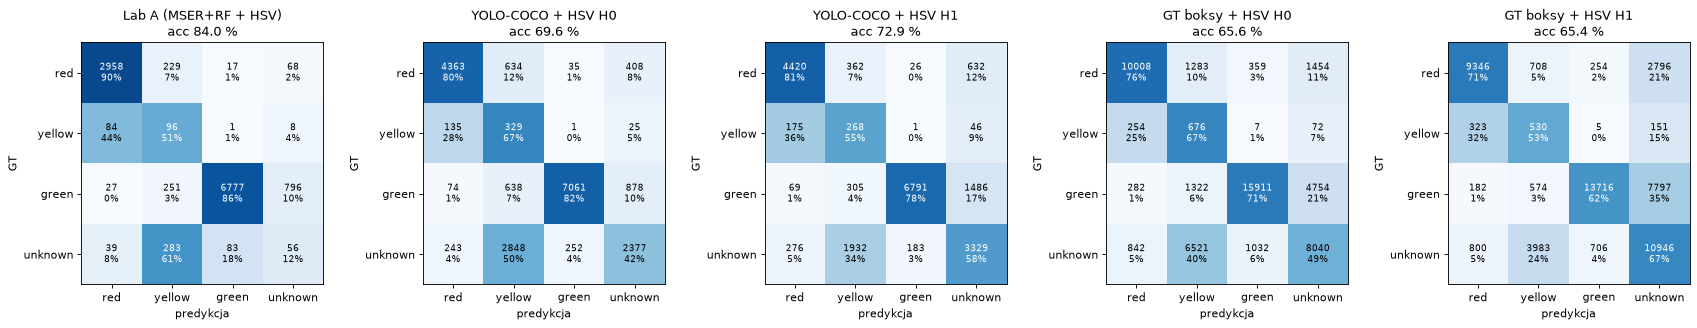

zapisano labB\assets\B06_kolor_recall_per_klasa.png


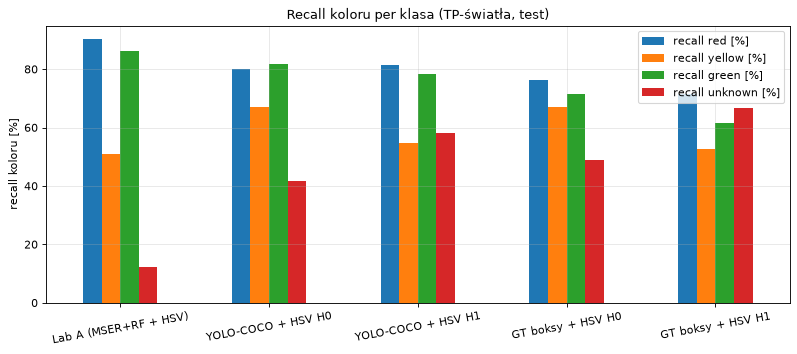

In [12]:
def color_table(names):
    rows = []
    for name, label in names:
        r = R(name)
        if not r or not r.get("color"):
            continue
        c = r["color"]
        rows.append({"metoda": label, "TP świateł": c["correctly_localized_lights"], "accuracy [%]": c["color_accuracy_percent"],
                     **{f"recall {k} [%]": 100 * v["recall"] for k, v in c["per_class"].items()}})
    return pd.DataFrame(rows)


def plot_confusions(names, file):
    names = [(n, l) for n, l in names if R(n) and R(n).get("color")]
    fig, axes = plt.subplots(1, len(names), figsize=(4.3 * len(names), 4))
    for ax, (name, label) in zip(np.atleast_1d(axes), names):
        cm = np.array(R(name)["color"]["confusion_matrix"], dtype=float)
        norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
        ax.grid(False)
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, f"{int(v)}\n{100 * norm[i, j]:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if norm[i, j] > 0.5 else "black")
        ax.set(xticks=range(4), yticks=range(4), xticklabels=COLORS, yticklabels=COLORS, xlabel="predykcja",
               ylabel="GT", title=f"{label}\nacc {R(name)['color']['color_accuracy_percent']:.1f} %")
    fig.tight_layout()
    save(fig, file)


COLOR_METHODS = [("labA_light_test", "Lab A (MSER+RF + HSV)"), ("hybrid_H0_test", "YOLO-COCO + HSV H0"),
                 ("hybrid_H1_test", "YOLO-COCO + HSV H1"), ("oracle_H0_test", "GT boksy + HSV H0"),
                 ("oracle_H1_test", "GT boksy + HSV H1")]
colors_df = color_table(COLOR_METHODS)
save_table(colors_df, "T03_kolor_na_TP", "Trafność koloru na poprawnie zlokalizowanych światłach (test)")
plot_confusions(COLOR_METHODS, "B05_kolor_macierze_pomylek")

ax = colors_df.set_index("metoda")[[c for c in colors_df.columns if c.startswith("recall")]].plot.bar(figsize=(12, 4.5), rot=10)
ax.set(ylabel="recall koloru [%]", xlabel="", title="Recall koloru per klasa (TP-światła, test)")
save(ax.figure, "B06_kolor_recall_per_klasa")

## 3. Zadanie 4 - porównanie z Lab A (ten sam test: 20 000 obrazów, IoU >= 0,5)

Progi wszystkich metod B zamrożone na val. FPS: end-to-end, batch 1 (GPU: RTX 3060 Laptop; CPU: pierwsze
500 obrazów testu). Lab A mierzony był wyłącznie na CPU. Wiersze "oracle" to nie detektory (boksy GT) - tylko kolor.
Bez fine-tuningu porównujemy tylko sygnalizatory; wiersz STOP jest informacyjny.

In [13]:
METHODS = [("hybrid_H0_test", "YOLO-COCO + HSV (H0)"), ("hybrid_H1_test", "YOLO-COCO + HSV (H1)"),
           (f"{BEST}_stop_test", "YOLO-COCO stop sign (vs wszystkie znaki)"),
           ("oracle_H0_test", "GT boksy + HSV (oracle H0)"), ("oracle_H1_test", "GT boksy + HSV (oracle H1)")]
METHODS = [(n, l) for n, l in METHODS if (RESULTS / f"{n}.json").exists()]
run("compare", [CODE / "compare.py", "--methods", *[f"{n}={l}" for n, l in METHODS]],
    [RESULTS / "comparison.csv"], [RESULTS / f"{n}.json" for n, _ in METHODS], force=True)

# FPS na CPU: detekcja (pierwsze N obrazów testu na CPU) + średni czas koloru HSV z przebiegu testowego
CPU_DET = mean_seconds(COCO_CPU)


def cpu_fps(name):
    if name.startswith("oracle"):
        return None
    color = mean_seconds(PRED / f"{name}.jsonl", "color_seconds") if name.startswith("hybrid") else 0.0
    return 1 / (CPU_DET + color)


table = pd.read_csv(RESULTS / "comparison.csv")
names = [None, None] + [n for n, _ in METHODS]  # dwa pierwsze wiersze = Lab A
table["FPS CPU"] = [r["fps"] if n is None else cpu_fps(n) for n, (_, r) in zip(names, table.iterrows())]
table.loc[table["method"].str.contains("oracle"), ["fps", "mean_detection_seconds"]] = np.nan  # oracle: brak detektora
table = table.rename(columns={"method": "metoda", "class": "klasa", "precision_percent": "P [%]", "recall_percent": "R [%]",
                              "f1_percent": "F1 [%]", "color_accuracy_percent": "kolor acc. (TP) [%]",
                              "mean_detection_seconds": "s/obraz", "fps": "FPS GPU", "hardware": "sprzęt"})
table.loc[table["sprzęt"] == "CPU", "FPS GPU"] = np.nan      # Lab A: tylko CPU
table.loc[table["metoda"].str.contains("oracle"), "sprzęt"] = "-"
table = table[table["klasa"] != "traffic_sign"].reset_index(drop=True)   # bez fine-tuningu nie porównujemy znaków
save_table(table, "T04_porownanie_test", "Porównanie na teście (20 000 obrazów, IoU >= 0.5)")

common = json.loads((RESULTS / "comparison_common_lights.json").read_text(encoding="utf-8"))
common_df = pd.DataFrame([{"metoda B": k, "wspólne światła": v["common_lights"], "Lab A acc [%]": v["first_accuracy_percent"],
                           "metoda B acc [%]": v["second_accuracy_percent"]} for k, v in common.items() if v])
save_table(common_df, "T05_kolor_te_same_swiatla", "Kolor na tych samych sygnalizatorach (trafionych przez A i B)")

[start 08:16:42] compare  (log: labB\runs\logs\compare.log)
    | method | class | precision_percent | recall_percent | f1_percent | color_accuracy_percent | mean_detection_seconds | fps | hardware |
    |---|---|---|---|---|---|---|---|---|
    | Lab A: MSER+Canny+RF | traffic_sign | 19.08 | 17.41 | 18.21 | - | 4.51 | 0.22 | CPU |
    | Lab A: MSER+Canny+RF + HSV | traffic_light | 20.58 | 22.29 | 21.40 | 83.98 | 3.50 | 0.29 | CPU |
    | Lab B: YOLO-COCO + HSV (H0) | traffic_light | 40.34 | 38.44 | 39.37 | 69.60 | 0.03 | 37.92 | NVIDIA GeForce RTX 3060 Laptop GPU |
    | Lab B: YOLO-COCO + HSV (H1) | traffic_light | 40.34 | 38.44 | 39.37 | 72.94 | 0.03 | 38.26 | NVIDIA GeForce RTX 3060 Laptop GPU |
    | Lab B: YOLO-COCO stop sign (vs wszystkie znaki) | stop_sign | 59.06 | 2.97 | 5.65 | - | 0.03 | 39.51 | NVIDIA GeForce RTX 3060 Laptop GPU |
    | Lab B: GT boksy + HSV (oracle H0) | traffic_light | 100.00 | 100.00 | 100.00 | 65.58 | 0.00 | 1093.43 | CPU |
    | Lab B: GT boksy + HSV (

,metoda,klasa,P [%],R [%],F1 [%],kolor acc. (TP) [%],s/obraz,FPS GPU,sprzęt,FPS CPU
0,Lab A: MSER+Canny+RF + HSV,traffic_light,20.58,22.29,21.40,83.98,3.50,NaN,CPU,0.29
1,Lab B: YOLO-COCO + HSV (H0),traffic_light,40.34,38.44,39.37,69.60,0.03,37.92,NVIDIA GeForce RTX 3060 Laptop GPU,6.38
2,Lab B: YOLO-COCO + HSV (H1),traffic_light,40.34,38.44,39.37,72.94,0.03,38.26,NVIDIA GeForce RTX 3060 Laptop GPU,6.39
3,Lab B: YOLO-COCO stop sign (vs wszystkie znaki),stop_sign,59.06,2.97,5.65,NaN,0.03,39.51,NVIDIA GeForce RTX 3060 Laptop GPU,6.42
4,Lab B: GT boksy + HSV (oracle H0),traffic_light,100.00,100.00,100.00,65.58,NaN,NaN,-,NaN
5,Lab B: GT boksy + HSV (oracle H1),traffic_light,100.00,100.00,100.00,65.39,NaN,NaN,-,NaN


zapisano labB\assets\tables\T05_kolor_te_same_swiatla.png + .csv


,metoda B,wspólne światła,Lab A acc [%],metoda B acc [%]
0,YOLO-COCO + HSV (H0),6149,83.41,83.82
1,YOLO-COCO + HSV (H1),6149,83.41,83.77
2,GT boksy + HSV (oracle H0),11773,83.98,84.24
3,GT boksy + HSV (oracle H1),11773,83.98,78.65


zapisano labB\assets\B07_porownanie_A_vs_B.png


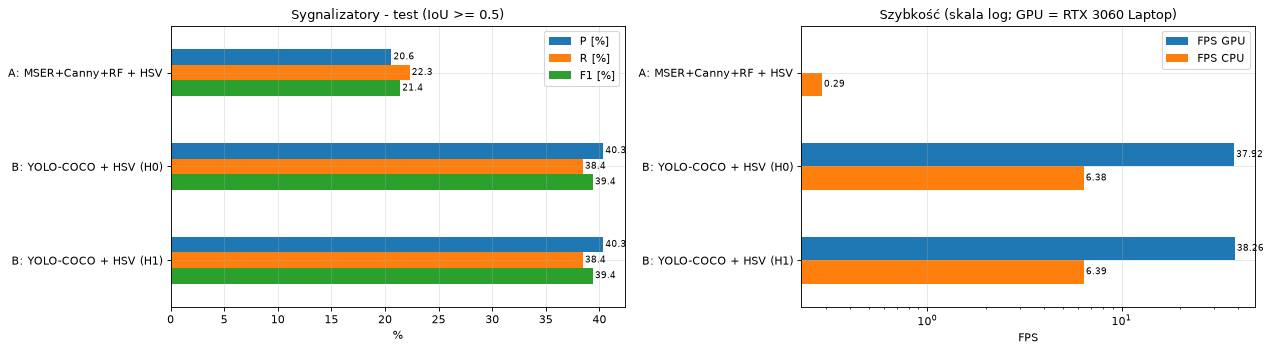

zapisano labB\assets\B08_f1_vs_fps.png


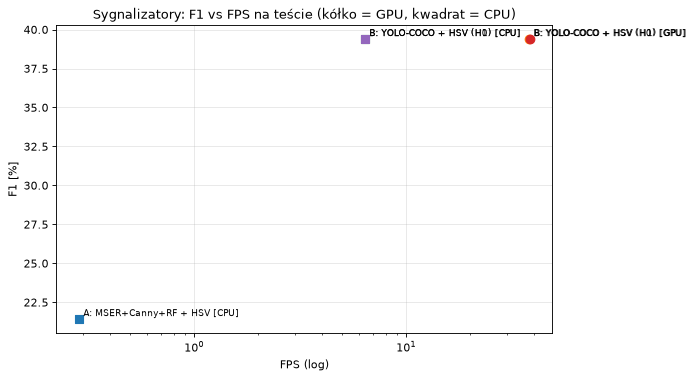

In [14]:
det = table[~table["metoda"].str.contains("oracle") & (table["klasa"] == "traffic_light")].copy()
det["etykieta"] = det["metoda"].str.replace("Lab B: ", "B: ").str.replace("Lab A: ", "A: ")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
det.set_index("etykieta")[["P [%]", "R [%]", "F1 [%]"]].plot.barh(ax=axes[0])
axes[0].set(title="Sygnalizatory - test (IoU >= 0.5)", xlabel="%", ylabel="")
axes[0].invert_yaxis()
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f", fontsize=8, padding=2)
det.set_index("etykieta")[["FPS GPU", "FPS CPU"]].plot.barh(ax=axes[1], logx=True)
axes[1].set(title="Szybkość (skala log; GPU = RTX 3060 Laptop)", xlabel="FPS", ylabel="")
axes[1].invert_yaxis()
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", fontsize=8, padding=2)
fig.tight_layout()
save(fig, "B07_porownanie_A_vs_B")

fig, ax = plt.subplots(figsize=(8, 5))
for _, row in det.iterrows():
    for col, marker, hw in (("FPS GPU", "o", "GPU"), ("FPS CPU", "s", "CPU")):
        if pd.notna(row[col]):
            ax.scatter(row[col], row["F1 [%]"], marker=marker, s=60)
            ax.annotate(f"{row['etykieta']} [{hw}]", (row[col], row["F1 [%]"]), fontsize=8, xytext=(4, 3),
                        textcoords="offset points")
ax.set(xscale="log", xlabel="FPS (log)", ylabel="F1 [%]", title="Sygnalizatory: F1 vs FPS na teście (kółko = GPU, kwadrat = CPU)")
save(fig, "B08_f1_vs_fps")

zapisano labB\assets\B09_swiatla_wg_rozmiaru.png


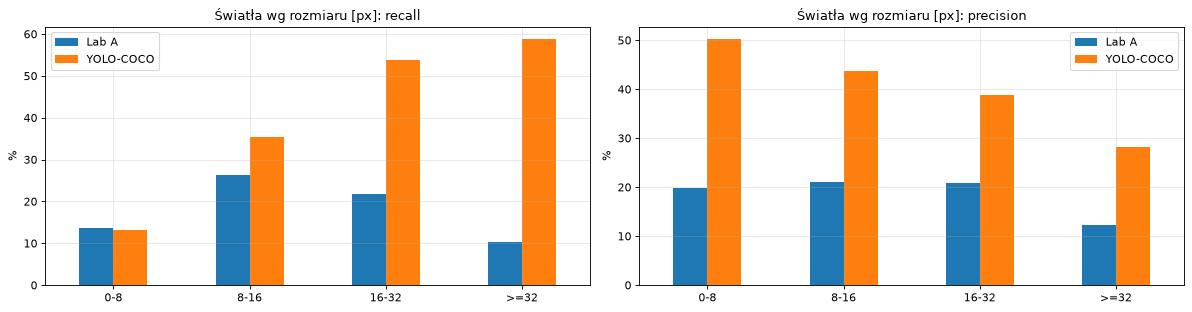

zapisano labB\assets\tables\T09_swiatla_wg_rozmiaru.png + .csv


,recall Lab A [%],recall YOLO-COCO [%],precision Lab A [%],precision YOLO-COCO [%]
0-8,13.56,13.08,19.84,50.24
8-16,26.21,35.42,21.06,43.76
16-32,21.70,53.79,20.86,38.71
>=32,10.37,58.82,12.35,28.27


zapisano labB\assets\B10_swiatla_wg_pory_dnia.png


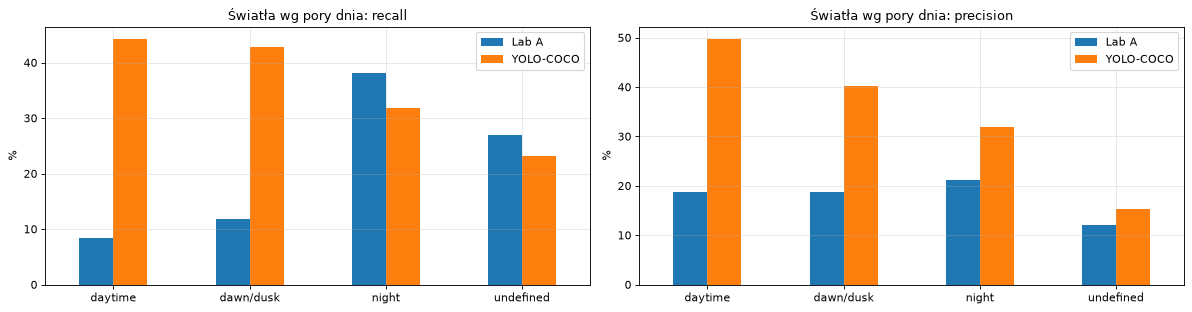

zapisano labB\assets\tables\T10_swiatla_wg_pory_dnia.png + .csv


,recall Lab A [%],recall YOLO-COCO [%],precision Lab A [%],precision YOLO-COCO [%]
daytime,8.42,44.26,18.80,49.73
dawn/dusk,11.76,42.84,18.74,40.10
night,38.08,31.83,21.14,31.92
undefined,26.92,23.08,12.07,15.38


In [15]:
def breakdown_plot(names, key, order, title, file):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    frames = {}
    for ax, metric in zip(axes, ("recall_percent", "precision_percent")):
        data = {label: {k: v[metric] for k, v in R(n)[key].items()} for n, label in names if R(n)}
        frame = pd.DataFrame(data)
        frame = frame.loc[[o for o in order if o in frame.index]]
        frames[metric.split("_")[0]] = frame
        frame.plot.bar(ax=ax, rot=0)
        ax.set(title=f"{title}: {metric.split('_')[0]}", ylabel="%", xlabel="")
    fig.tight_layout()
    save(fig, file)
    joined = pd.concat(frames, axis=1)
    joined.columns = [f"{m} {l} [%]" for m, l in joined.columns]
    save_table(joined, file.replace("B", "T", 1), title, index=True)


SIZES = ["0-8", "8-16", "16-32", ">=32"]
TIMES = ["daytime", "dawn/dusk", "night", "undefined"]
LIGHTS = [("labA_light_test", "Lab A"), (f"{BEST}_light_test", "YOLO-COCO")]
breakdown_plot(LIGHTS, "by_size", SIZES, "Światła wg rozmiaru [px]", "B09_swiatla_wg_rozmiaru")
breakdown_plot(LIGHTS, "by_timeofday", TIMES, "Światła wg pory dnia", "B10_swiatla_wg_pory_dnia")

## 4. Zadanie 5 - przykłady błędów

Na teście, dla najlepszej hybrydy YOLO-COCO + HSV (próg z val). Kolory ramek: cyjan = TP, magenta = FP,
żółte przerywane = nie wykryte GT (FN).

analizowany wariant: hybrid_H1_test
FP: 30020, FN: 32516, zły kolor (wśród TP): 5493
zapisano labB\assets\B11_bledy_FP.png


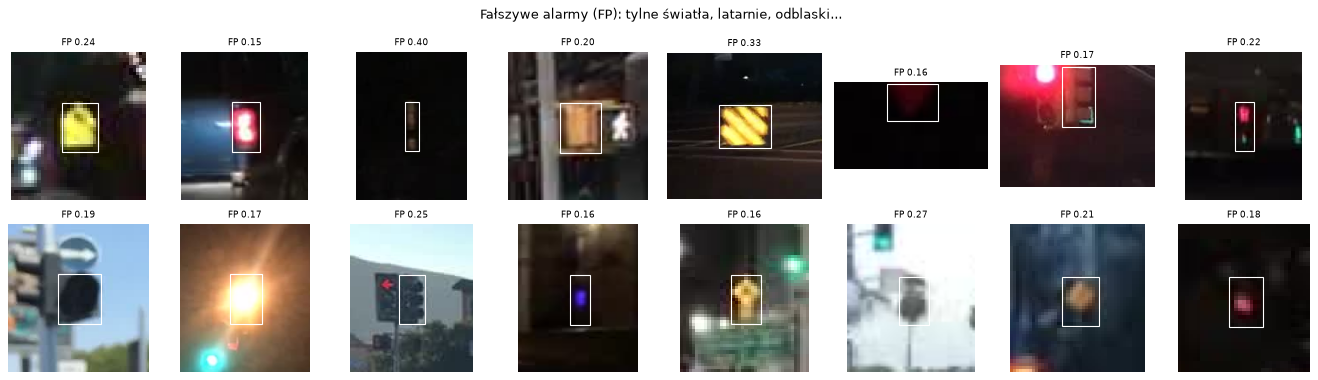

zapisano labB\assets\B12_bledy_FN.png


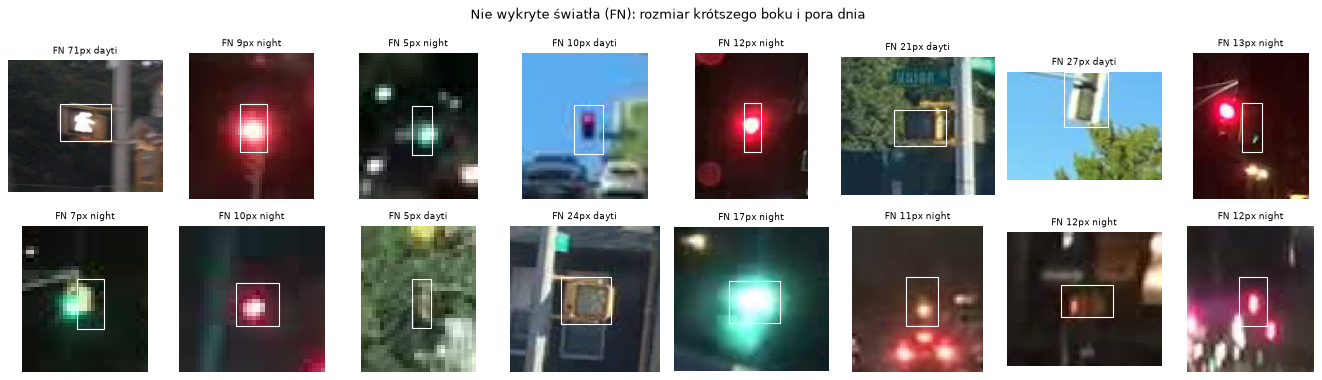

zapisano labB\assets\B13_bledy_kolor.png


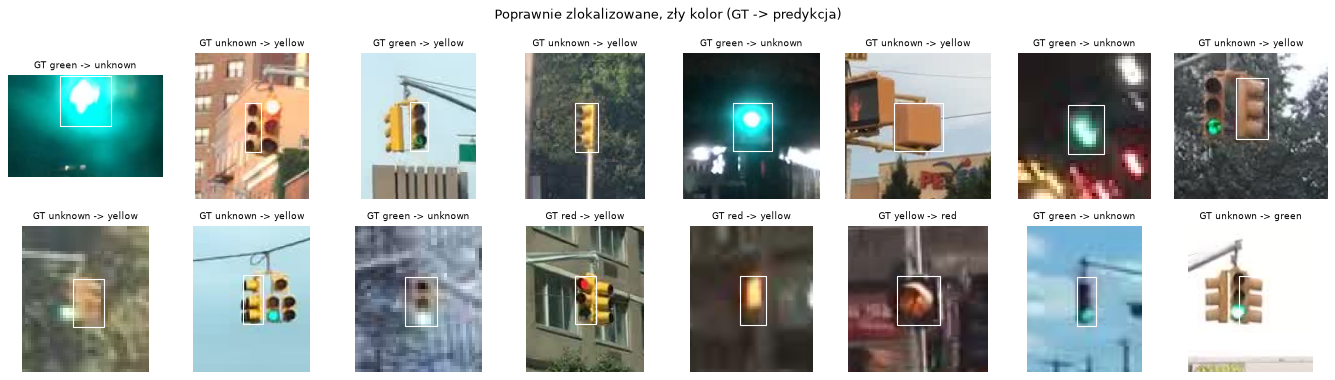

In [16]:
HYB = max(("hybrid_H0_test", "hybrid_H1_test"), key=lambda n: R(n)["color"]["color_accuracy_percent"])
hyb_rows = read_jsonl(PRED / f"{HYB}.jsonl")
print("analizowany wariant:", HYB)

per_image, fp_items, fn_items, color_items = [], [], [], []
for row in hyb_rows:
    ann = load_annotation("test", row["image_id"])
    res = match_predictions(row["predictions"], ann["traffic_light"], 0.5)
    per_image.append((row["image_id"], res["false_positive"], res["false_negative"], ann["timeofday"]))
    for m in res["matched_predictions"]:
        if m["result"] == "false_positive":
            fp_items.append((row["image_id"], m["box"], f"FP {m['score']:.2f}"))
        elif m["color"] != ann["light_colors"][m["matched_target_index"]]:
            color_items.append((row["image_id"], m["box"], f"GT {ann['light_colors'][m['matched_target_index']]} -> {m['color']}"))
    for miss in res["unmatched_targets"]:
        side = min(miss["box"][2] - miss["box"][0], miss["box"][3] - miss["box"][1])
        fn_items.append((row["image_id"], miss["box"], f"FN {side:.0f}px {ann['timeofday'][:5]}"))
print(f"FP: {len(fp_items)}, FN: {len(fn_items)}, zły kolor (wśród TP): {len(color_items)}")


def crop_gallery(items, title, file, n=16, cols=8, seed=0):
    items = random.Random(seed).sample(items, min(n, len(items)))
    if not items:
        print("brak przykładów:", title)
        return
    rows_n = int(np.ceil(len(items) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(2.1 * cols, 2.4 * rows_n))
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, (image_id, box, label) in zip(np.atleast_1d(axes).flat, items):
        with Image.open(IMAGES / "test" / f"{image_id}.jpg") as img:
            w, h = box[2] - box[0], box[3] - box[1]
            pad = max(12, 1.0 * max(w, h))
            x1, y1 = int(max(0, box[0] - pad)), int(max(0, box[1] - pad))
            crop = img.convert("RGB").crop((x1, y1, int(min(img.width, box[2] + pad)), int(min(img.height, box[3] + pad))))
        ax.imshow(crop)
        draw_box(ax, [box[0] - x1, box[1] - y1, box[2] - x1, box[3] - y1], "white", lw=1)
        ax.set_title(label, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    save(fig, file)


crop_gallery(fp_items, "Fałszywe alarmy (FP): tylne światła, latarnie, odblaski...", "B11_bledy_FP")
crop_gallery(fn_items, "Nie wykryte światła (FN): rozmiar krótszego boku i pora dnia", "B12_bledy_FN")
crop_gallery(color_items, "Poprawnie zlokalizowane, zły kolor (GT -> predykcja)", "B13_bledy_kolor")

zapisano labB\assets\B14_bledy_najgorsze_obrazy.png


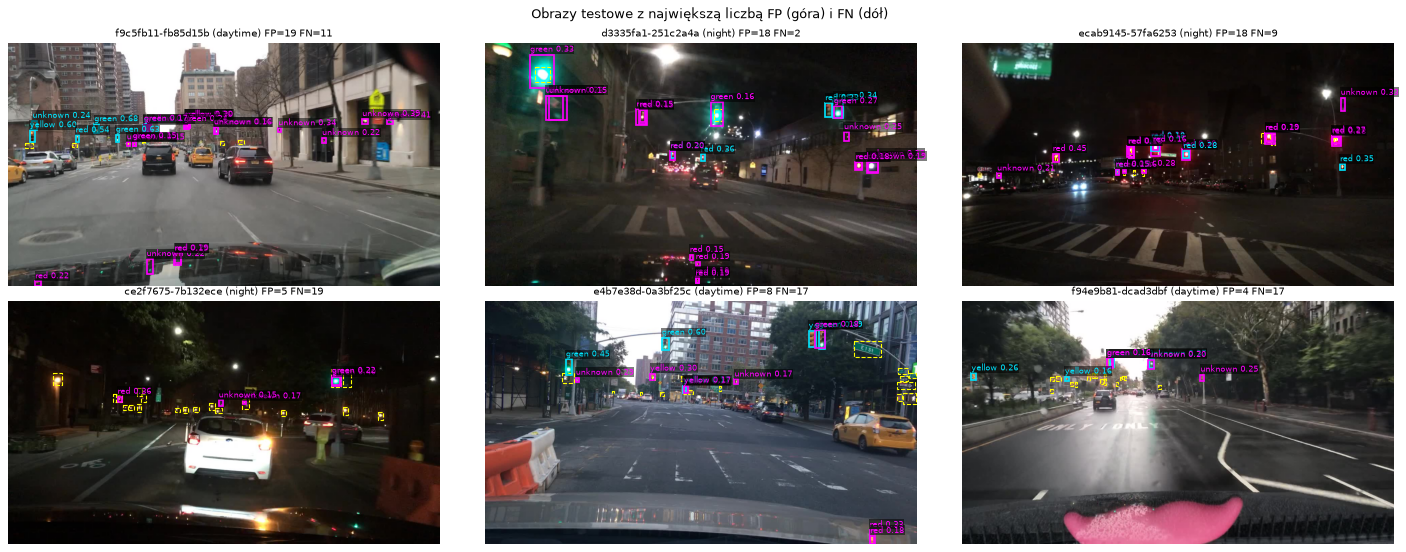

pojedyncze obrazy: labB\assets\examples/


In [17]:
# całe obrazy z największą liczbą FP i FN (siatka + pojedyncze pliki)
hyb_by_id = {r["image_id"]: r for r in hyb_rows}
worst_fp = sorted(per_image, key=lambda t: -t[1])[:3]
worst_fn = sorted(per_image, key=lambda t: -t[2])[:3]
HYB_LAYERS = [("traffic_light", is_light, 0)]
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, (kind, (image_id, fp, fn, tod)) in zip(axes.flat, [("FP", t) for t in worst_fp] + [("FN", t) for t in worst_fn]):
    title = f"{image_id} ({tod}) FP={fp} FN={fn}"
    show_image(ax, "test", hyb_by_id[image_id], HYB_LAYERS, title=title)
    save_example("test", hyb_by_id[image_id], HYB_LAYERS, f"{HYB}: {title}", f"najwiecej_{kind}_{image_id}")
fig.suptitle("Obrazy testowe z największą liczbą FP (góra) i FN (dół)")
fig.tight_layout()
save(fig, "B14_bledy_najgorsze_obrazy")

# kilka typowych obrazów testowych (dzień / noc) z hybrydą - pojedyncze pliki na slajdy
rng = random.Random(3)
for tod in ("daytime", "night"):
    ids = [i for i, fp, fn, t in per_image if t == tod and len(hyb_by_id[i]["predictions"]) >= 3]
    for image_id in rng.sample(ids, min(3, len(ids))):
        save_example("test", hyb_by_id[image_id], HYB_LAYERS, f"{HYB} ({tod}): {image_id}", f"test_{tod}_{image_id}")
print(f"pojedyncze obrazy: {EXAMPLES.relative_to(REPO)}/")

zapisano labB\assets\tables\T11_trafione_swiatla_A_vs_B.png + .csv


,tylko Lab A,tylko YOLO-COCO,oba,żaden
0,5624,14152,6149,26892


zapisano labB\assets\B15_tylko_labA.png


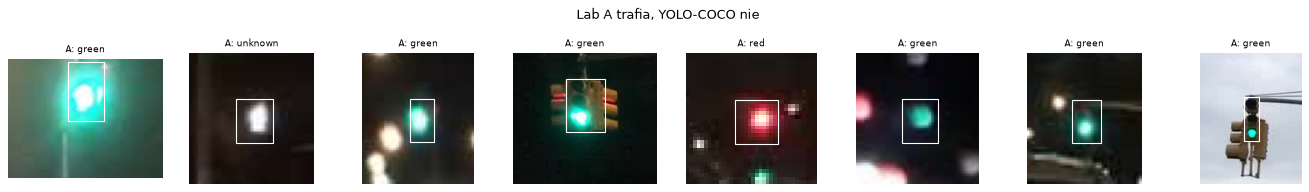

zapisano labB\assets\B16_tylko_yolo.png


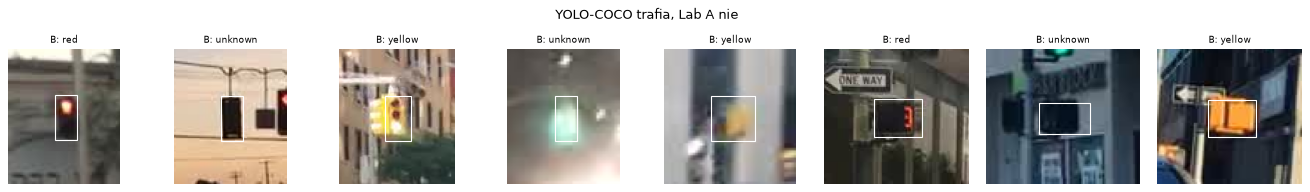

zapisano labB\assets\B17_stop_TP.png


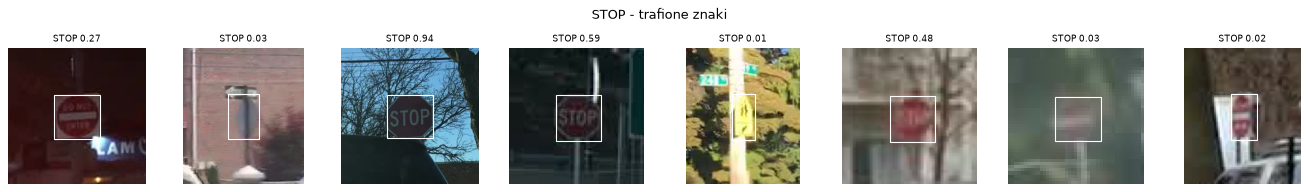

zapisano labB\assets\B18_stop_FP.png


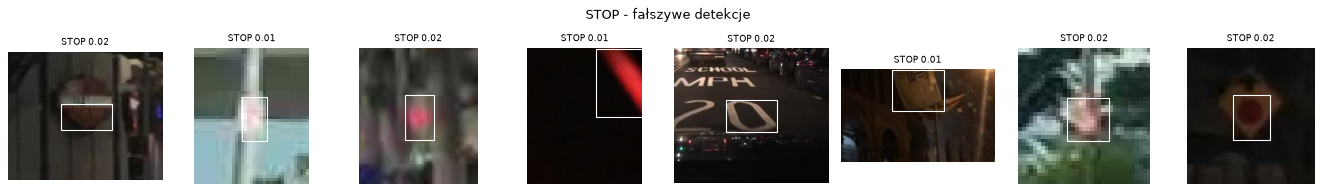

In [18]:
# te same sygnalizatory: trafione przez Lab A, a nie przez YOLO - i odwrotnie
def matched(name):
    path = RUNS / "eval" / f"{name}_matched.json"
    return {(m["image_id"], m["index"]): m for m in json.loads(path.read_text())}


a, b = matched("labA_light_test"), matched(HYB)
gt_cache = {}


def gt_box(image_id, index):
    if image_id not in gt_cache:
        gt_cache[image_id] = load_annotation("test", image_id)["traffic_light"]
    return gt_cache[image_id][index]


only_a = [(k[0], gt_box(*k), f"A: {a[k]['predicted_color']}") for k in sorted(a.keys() - b.keys())]
only_b = [(k[0], gt_box(*k), f"B: {b[k]['predicted_color']}") for k in sorted(b.keys() - a.keys())]
overlap = pd.DataFrame([{"tylko Lab A": len(only_a), "tylko YOLO-COCO": len(only_b), "oba": len(a.keys() & b.keys()),
                         "żaden": R("labA_light_test")["ground_truth_objects"] - len(a.keys() | b.keys())}])
save_table(overlap, "T11_trafione_swiatla_A_vs_B", "GT-sygnalizatory trafione przez Lab A i YOLO-COCO (test)")
crop_gallery(only_a, "Lab A trafia, YOLO-COCO nie", "B15_tylko_labA", n=8)
crop_gallery(only_b, "YOLO-COCO trafia, Lab A nie", "B16_tylko_yolo", n=8)

# STOP: trafienia i fałszywe detekcje na teście
stop_tp, stop_fp = [], []
for row in read_jsonl(COCO_TEST):
    stops = [p for p in row["predictions"] if p["class"] == "stop_sign" and p["score"] >= T_STOP]
    if stops:
        res = match_predictions(stops, load_annotation("test", row["image_id"])["traffic_sign"], 0.5)
        for m in res["matched_predictions"]:
            (stop_tp if m["result"] == "true_positive" else stop_fp).append((row["image_id"], m["box"], f"STOP {m['score']:.2f}"))
crop_gallery(stop_tp, "STOP - trafione znaki", "B17_stop_TP", n=8)
crop_gallery(stop_fp, "STOP - fałszywe detekcje", "B18_stop_FP", n=8)

## Podsumowanie (liczby generowane z `labB/results/`)

In [19]:
A_L = R("labA_light_test")
H, S = R(HYB), R(f"{BEST}_stop_test")
lines = [
    f"* **Wybrany YOLO-COCO:** {BEST} (best F1 na val1000 = {BEST_ROW['F1 [%]']:.2f} %, próg {T_LIGHT:.3f}).",
    f"* **Światła (test):** Lab A F1 {A_L['f1_percent']:.2f} % (P {A_L['precision_percent']:.1f}, R {A_L['recall_percent']:.1f}) "
    f"-> YOLO-COCO F1 {H['f1_percent']:.2f} % (P {H['precision_percent']:.1f}, R {H['recall_percent']:.1f}).",
    f"* **Kolor (TP):** Lab A {A_L['color']['color_accuracy_percent']:.2f} %, hybryda H0 {R('hybrid_H0_test')['color']['color_accuracy_percent']:.2f} %, "
    f"H1 {R('hybrid_H1_test')['color']['color_accuracy_percent']:.2f} %, oracle H0 {R('oracle_H0_test')['color']['color_accuracy_percent']:.2f} %, "
    f"oracle H1 {R('oracle_H1_test')['color']['color_accuracy_percent']:.2f} %.",
    f"* **Szybkość:** Lab A {1 / LAB_A_RESULTS['detection'][1]['mean_detection_seconds']:.2f} FPS (CPU); "
    f"YOLO-COCO + HSV {H['fps']:.1f} FPS (GPU), {cpu_fps(HYB):.2f} FPS (CPU).",
    f"* **STOP:** {S['true_positive'] + S['false_positive']} detekcji, precyzja {S['precision_percent']:.1f} %, "
    f"pokrycie znaków BDD {S['recall_percent']:.2f} %.",
]
for size in ("0-8", "8-16"):
    if size in H["by_size"]:
        lines.append(f"* **Małe światła {size} px:** recall Lab A {A_L['by_size'].get(size, {}).get('recall_percent', float('nan')):.1f} %, "
                     f"YOLO-COCO {H['by_size'][size]['recall_percent']:.1f} %.")
summary_md = "\n".join(lines)
(RESULTS / "summary.md").write_text(summary_md + "\n", encoding="utf-8")
display(Markdown(summary_md))
print("\nZapisane pliki do prezentacji:")
for folder in (ASSETS, TABLES, EXAMPLES):
    files = sorted(p.name for p in folder.glob("*.png"))
    print(f"  {folder.relative_to(REPO)}/ ({len(files)} PNG)")

* **Wybrany YOLO-COCO:** coco_yolo11s_1280 (best F1 na val1000 = 42.67 %, próg 0.147).
* **Światła (test):** Lab A F1 21.40 % (P 20.6, R 22.3) -> YOLO-COCO F1 39.37 % (P 40.3, R 38.4).
* **Kolor (TP):** Lab A 83.98 %, hybryda H0 69.60 %, H1 72.94 %, oracle H0 65.58 %, oracle H1 65.39 %.
* **Szybkość:** Lab A 0.29 FPS (CPU); YOLO-COCO + HSV 38.3 FPS (GPU), 6.39 FPS (CPU).
* **STOP:** 3464 detekcji, precyzja 59.1 %, pokrycie znaków BDD 2.97 %.
* **Małe światła 0-8 px:** recall Lab A 13.6 %, YOLO-COCO 13.1 %.
* **Małe światła 8-16 px:** recall Lab A 26.2 %, YOLO-COCO 35.4 %.


Zapisane pliki do prezentacji:
  labB\assets/ (18 PNG)
  labB\assets\tables/ (9 PNG)
  labB\assets\examples/ (21 PNG)


### Wnioski - do uzupełnienia po przejrzeniu wyników

Hipotezy z planu do zweryfikowania na podstawie tabel i wykresów powyżej:
1. YOLO ma wyższą precyzję niż metoda klasyczna i FPS wyższe o rzędy wielkości (także na CPU).
2. Recall YOLO-COCO ograniczają małe obiekty - duży wpływ `imgsz` (sekcja 1.1, rozbicie wg rozmiaru).
3. Jakość koloru zależy od ROI (oracle vs hybryda; H0 vs H1); `yellow` i `unknown` pozostają najtrudniejsze.
4. Model COCO zna wyłącznie `stop sign`, więc bez fine-tuningu nie da się wykrywać ogólnej klasy `traffic sign`.